# 05 — Analyse comparative, choix de l'approche et recommandations

Ce notebook rassemble les résultats des notebooks 03 (limite d'élasticité) et 04
(résilience Charpy), qui doivent avoir été exécutés avant (ils enregistrent leurs
prédictions dans `results/`).

Plan :
1. Les métriques et pourquoi
2. Comparaison globale des modèles
3. Métrique de décision : accepter ou refuser une soudure
4. Les écarts sont-ils significatifs ?
5. Choix de l'approche la plus appropriée
6. Ce que le modèle a appris : effet de chaque variable
7. Recommandations

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

sys.path.insert(0, str(Path.cwd().parent / "src"))
import preprocessing
import welddb

sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
os.environ["PYTHONWARNINGS"] = "ignore:`sklearn.utils.parallel.delayed`:UserWarning"  # processus parallèles
RESULTS = Path.cwd().parent / "results"

TARGETS = {
    "Limite d'élasticité": {"file": "ys", "unit": "MPa", "tolerance": 50, "threshold": 420},
    "Résilience Charpy": {"file": "charpy", "unit": "J", "tolerance": 20, "threshold": 47},
}
oof = {name: pd.read_csv(RESULTS / f"{t['file']}_oof.csv") for name, t in TARGETS.items()}
fold_scores = {name: pd.read_csv(RESULTS / f"{t['file']}_scores.csv") for name, t in TARGETS.items()}
MODELS = ["Moyenne (référence)", "Température seule (référence)", "Régression linéaire", "k-NN", "SVR", "Forêt aléatoire",
          "Gradient boosting"]

## 1. Les métriques et pourquoi

Notations : yᵢ valeur mesurée, ŷᵢ valeur prédite, ȳ moyenne, n nombre de soudures de test.

| Métrique | Formule | Pourquoi |
|---|---|---|
| **RMSE** | √( (1/n) Σ (yᵢ − ŷᵢ)² ) | Erreur dans l'unité physique ; pénalise les grosses erreurs, les plus dangereuses |
| **MAE** | (1/n) Σ \|yᵢ − ŷᵢ\| | Erreur « typique », moins sensible aux quelques soudures très mal prédites |
| **R²** | 1 − Σ (yᵢ − ŷᵢ)² / Σ (yᵢ − ȳ)² | Compare les deux cibles entre elles (sans unité) : 0 = pas mieux que la moyenne |
| **Part dans la tolérance** | part des soudures avec \|yᵢ − ŷᵢ\| ≤ tolérance | Lecture « métier » : à ±50 MPa ou ±20 J près, le modèle a-t-il raison ? |
| **Taux de fausse acceptation** | non conformes prédites conformes / non conformes | **L'erreur dangereuse** : une soudure trop faible acceptée |
| **Taux de faux rejet** | conformes prédites non conformes / conformes | L'erreur coûteuse : une bonne soudure refaite ou retestée pour rien |
| **AUC** (aire sous la courbe ROC) | probabilité qu'une soudure non conforme tirée au hasard ait une prédiction plus basse qu'une soudure conforme tirée au hasard | Capacité à **classer** les soudures, indépendamment du seuil et de la marge : 0,5 = hasard, 1 = parfait |

**Seuils de conformité** : 420 MPa de limite d'élasticité minimale (classe « 42 » de la norme
EN ISO 2560-A pour les électrodes enrobées) et 47 J à la température d'essai (critère courant
de la même norme). Ces seuils servent à illustrer ; un industriel utiliserait ceux de son
cahier des charges.

Toutes les métriques sont calculées sur les **prédictions hors pli** des notebooks 03 et
04 : chaque soudure est prédite par un modèle qui n'a jamais vu sa publication. RMSE, MAE et
R² sont des moyennes sur les 5 plis ; les autres métriques portent sur toutes les lignes.
L'**incertitude** sur le RMSE est estimée par bootstrap sur les publications (section 4).

## 2. Comparaison globale des modèles

In [2]:
rows = []
for target, t in TARGETS.items():
    o = oof[target]
    for model in MODELS:
        col = f"pred_{model}"
        if col not in o:
            continue
        s = fold_scores[target].query("modèle == @model")
        rows.append({"cible": target, "modèle": model,
                     f"RMSE": s["RMSE"].mean(), "RMSE écart-type": s["RMSE"].std(),
                     "MAE": s["MAE"].mean(), "R²": s["R²"].mean(),
                     "dans la tolérance (%)": 100 * np.mean(np.abs(o[col] - o["mesure"]) <= t["tolerance"])})
comparison = pd.DataFrame(rows).set_index(["cible", "modèle"])
comparison.round(2)

RMSE  RMSE écart-type  \
cible               modèle                                                   
Limite d'élasticité Moyenne (référence)             92.59            16.08   
                    Régression linéaire            105.27            22.14   
                    k-NN                            88.07            25.87   
                    SVR                             66.75            11.83   
                    Forêt aléatoire                 67.48            11.72   
                    Gradient boosting               62.93             7.33   
Résilience Charpy   Moyenne (référence)             51.22             4.28   
                    Température seule (référence)   45.05             7.64   
                    Régression linéaire             67.20            35.78   
                    k-NN                            49.13             4.73   
                    SVR                             39.69             8.14   
                    Forêt aléatoire                 45.11            10.27   
                    Gradient boosting               46.59             7.88   

                                                     MAE    R²  \
cible               modèle                                       
Limite d'élasticité Moyenne (référence)            72.08 -0.06   
                    Régression linéaire            80.45 -0.41   
                    k-NN                           66.43  0.05   
                    SVR                            48.83  0.45   
                    Forêt aléatoire                49.66  0.44   
                    Gradient boosting              46.12  0.50   
Résilience Charpy   Moyenne (référence)            39.90 -0.18   
                    Température seule (référence)  33.21  0.03   
                    Régression linéaire            54.17 -1.35   
                    k-NN                           37.72 -0.09   
                    SVR                            30.53  0.28   
                    Forêt aléatoire                34.24  0.07   
                    Gradient boosting              34.78  0.00   

                                                   dans la tolérance (%)  
cible               modèle                                                
Limite d'élasticité Moyenne (référence)                            43.21  
                    Régression linéaire                            44.10  
                    k-NN                                           50.38  
                    SVR                                            64.10  
                    Forêt aléatoire                                61.03  
                    Gradient boosting                              65.51  
Résilience Charpy   Moyenne (référence)                            47.21  
                    Température seule (référence)                  44.60  
                    Régression linéaire                            31.74  
                    k-NN                                           41.75  
                    SVR                                            42.43  
                    Forêt aléatoire                                39.59  
                    Gradient boosting                              42.09

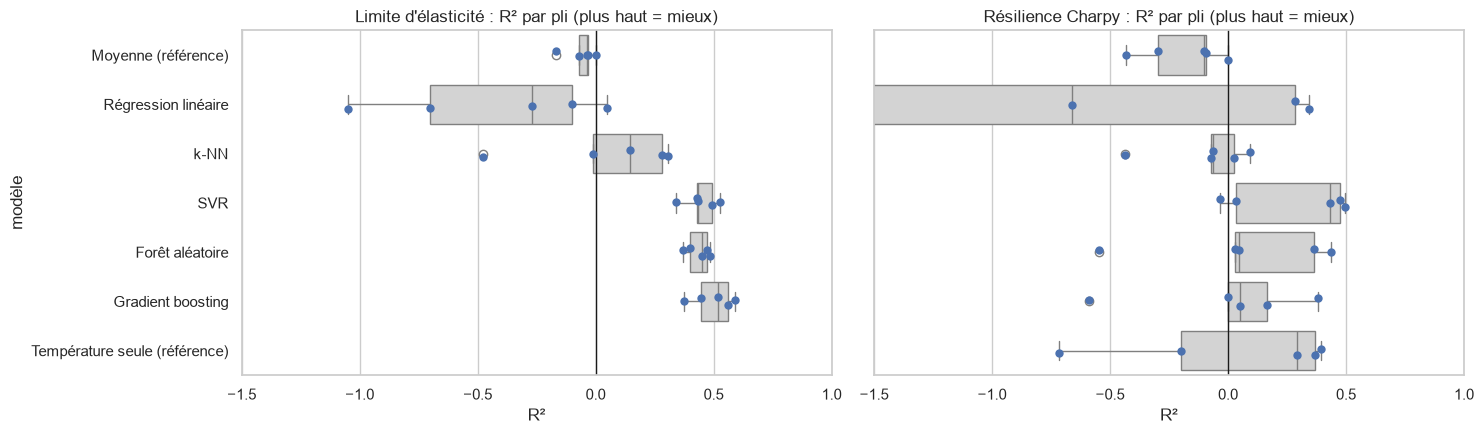

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, target in zip(axes, TARGETS):
    s = fold_scores[target]
    order = [m for m in MODELS if m in set(s["modèle"])]
    sns.boxplot(data=s, y="modèle", x="R²", order=order, ax=ax, color="lightgrey")
    sns.stripplot(data=s, y="modèle", x="R²", order=order, ax=ax, color="C0", size=6)
    ax.axvline(0, color="k", lw=1)
    ax.set_xlim(-1.5, 1); ax.set_title(f"{target} : R² par pli (plus haut = mieux)")
plt.tight_layout();

**Lecture.**
- Pour la limite d'élasticité, **le gradient boosting est le meilleur modèle** (≈ 63 MPa,
  R² ≈ 0,50), devant le SVR et la forêt aléatoire (≈ 67 MPa). Pour le Charpy, **seul le SVR
  fait nettement mieux que les références**. Sur les deux cibles, la régression linéaire et
  le k-NN font à peine mieux, voire moins bien, que la simple moyenne.
- **La limite d'élasticité est bien mieux prédite que la ténacité** (R² ≈ 0,50 contre 0,28
  au mieux). Pour le Charpy, la forêt aléatoire et le gradient boosting ne font pas mieux
  qu'un modèle qui ne connaît que la température d'essai.
- La « part dans la tolérance » du Charpy est trompeuse pour la moyenne : beaucoup de lignes
  valent 100 J (notebook 04) et la moyenne (≈ 88 J) tombe souvent à moins de 20 J d'elles.
  C'est un exemple de l'intérêt de croiser plusieurs métriques.

## 3. Métrique de décision : accepter ou refuser une soudure

Usage industriel envisagé : prédire la propriété d'une nouvelle recette et l'accepter si la
prédiction dépasse le seuil de conformité.

In [4]:
def decision_rates(measured, predicted, threshold, margin=0):
    accepted = predicted >= threshold + margin
    bad = measured < threshold
    return {"fausse acceptation (%)": 100 * (accepted & bad).sum() / bad.sum(),
            "faux rejet (%)": 100 * (~accepted & ~bad).sum() / (~bad).sum()}

rows = []
for target, t in TARGETS.items():
    o = oof[target]
    print(f"{target} : {100 * (o['mesure'] < t['threshold']).mean():.0f} % de soudures non conformes "
          f"(< {t['threshold']} {t['unit']})")
    for model in MODELS:
        if f"pred_{model}" in o:
            # AUC : la soudure est d'autant plus suspecte que sa prédiction est basse.
            # Sans objet pour la moyenne, dont la prédiction ne varie qu'entre les plis.
            auc = (np.nan if model == "Moyenne (référence)"
                   else roc_auc_score(o["mesure"] < t["threshold"], -o[f"pred_{model}"]))
            rows.append({"cible": target, "modèle": model,
                         **decision_rates(o["mesure"], o[f"pred_{model}"], t["threshold"]), "AUC": auc})
pd.DataFrame(rows).set_index(["cible", "modèle"]).round({"fausse acceptation (%)": 0, "faux rejet (%)": 0, "AUC": 2})

Limite d'élasticité : 16 % de soudures non conformes (< 420 MPa)
Résilience Charpy : 28 % de soudures non conformes (< 47 J)


fausse acceptation (%)  \
cible               modèle                                                  
Limite d'élasticité Moyenne (référence)                             100.0   
                    Régression linéaire                              63.0   
                    k-NN                                             74.0   
                    SVR                                              45.0   
                    Forêt aléatoire                                  70.0   
                    Gradient boosting                                45.0   
Résilience Charpy   Moyenne (référence)                             100.0   
                    Température seule (référence)                    63.0   
                    Régression linéaire                              77.0   
                    k-NN                                            100.0   
                    SVR                                              64.0   
                    Forêt aléatoire                                  96.0   
                    Gradient boosting                                77.0   

                                                   faux rejet (%)   AUC  
cible               modèle                                               
Limite d'élasticité Moyenne (référence)                       0.0   NaN  
                    Régression linéaire                      11.0  0.74  
                    k-NN                                      2.0  0.68  
                    SVR                                       4.0  0.85  
                    Forêt aléatoire                           1.0  0.88  
                    Gradient boosting                         3.0  0.92  
Résilience Charpy   Moyenne (référence)                       0.0   NaN  
                    Température seule (référence)             6.0  0.70  
                    Régression linéaire                       7.0  0.63  
                    k-NN                                      0.0  0.66  
                    SVR                                       3.0  0.82  
                    Forêt aléatoire                           2.0  0.75  
                    Gradient boosting                         4.0  0.73

Sans précaution, **le SVR et le gradient boosting acceptent à tort près de la moitié des
soudures trop faibles** pour la limite d'élasticité (45 %), et la forêt aléatoire encore
plus. Pour le Charpy, le SVR fait le moins d'erreurs dangereuses (64 %, contre 77 % pour le
gradient boosting et 96 % pour la forêt). Les modèles « tirent vers la moyenne » : ils prédisent rarement
des valeurs très basses. Le remède classique est une **marge de sécurité** : on n'accepte
que si la prédiction dépasse le seuil d'une certaine marge.

L'**AUC** mesure ce que le modèle peut faire une fois la marge bien réglée : elle ne dépend
que de l'ordre des prédictions. Pour la limite d'élasticité, le gradient boosting classe le
mieux les soudures (0,92, contre 0,85 pour le SVR) ; pour le Charpy, c'est le SVR (0,82, seul
nettement au-dessus de la température seule, 0,70).

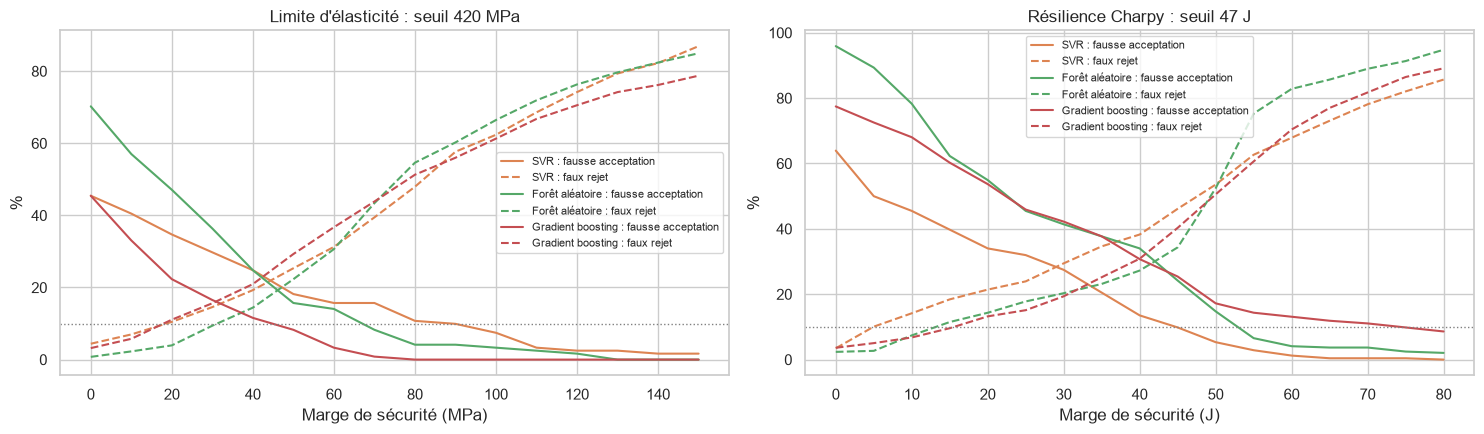

In [5]:
margins = {"Limite d'élasticité": np.arange(0, 151, 10), "Résilience Charpy": np.arange(0, 81, 5)}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (target, t) in zip(axes, TARGETS.items()):
    o = oof[target]
    for model, c in [("SVR", "C1"), ("Forêt aléatoire", "C2"), ("Gradient boosting", "C3")]:
        r = pd.DataFrame([decision_rates(o["mesure"], o[f"pred_{model}"], t["threshold"], m) for m in margins[target]])
        ax.plot(margins[target], r["fausse acceptation (%)"], "-", color=c, label=f"{model} : fausse acceptation")
        ax.plot(margins[target], r["faux rejet (%)"], "--", color=c, label=f"{model} : faux rejet")
    ax.axhline(10, color="grey", lw=1, ls=":")
    ax.set_xlabel(f"Marge de sécurité ({t['unit']})"); ax.set_ylabel("%")
    ax.set_title(f"{target} : seuil {t['threshold']} {t['unit']}"); ax.legend(fontsize=8)
plt.tight_layout();

**Choisir la marge sans tricher.** Lire sur ce graphique la marge qui donne 10 % de fausse
acceptation, c'est régler la marge sur les soudures mêmes qui servent à l'évaluer : les taux
obtenus seraient optimistes (même problème que choisir les hyperparamètres sur le pli de
test). On choisit donc la marge **en validation croisée groupée par publication** : pour
chacun des 5 groupes de publications, la marge retenue est la plus petite qui donne au plus
10 % de fausse acceptation sur les **autres** publications, et les taux sont mesurés sur ce
groupe. Les taux ci-dessous sont ceux qu'on peut attendre sur des publications nouvelles.

In [6]:
def cross_validated_margin(o, model, threshold, grid, max_false_accept=10):
    """Marge choisie sur 4/5 des publications, taux mesurés sur le 1/5 restant."""
    pred, measured = o[f"pred_{model}"].to_numpy(), o["mesure"].to_numpy()
    accepted, chosen = np.zeros(len(o), dtype=bool), []
    for train, test in GroupKFold(n_splits=5).split(o, groups=o["publication"]):
        m = next((m for m in grid if decision_rates(measured[train], pred[train], threshold, m)
                  ["fausse acceptation (%)"] <= max_false_accept), grid[-1])
        chosen.append(int(m))
        accepted[test] = pred[test] >= threshold + m
    bad = measured < threshold
    return {"marges choisies": chosen,
            "fausse acceptation (%)": 100 * (accepted & bad).sum() / bad.sum(),
            "faux rejet (%)": 100 * (~accepted & ~bad).sum() / (~bad).sum()}

rows = []
for target, t in TARGETS.items():
    for model in ["SVR", "Forêt aléatoire", "Gradient boosting"]:
        rows.append({"cible": target, "modèle": model,
                     **cross_validated_margin(oof[target], model, t["threshold"], margins[target])})
pd.DataFrame(rows).set_index(["cible", "modèle"]).round(0)

marges choisies  \
cible               modèle                                       
Limite d'élasticité SVR                [80, 50, 100, 100, 100]   
                    Forêt aléatoire       [70, 60, 80, 70, 70]   
                    Gradient boosting     [50, 40, 60, 60, 50]   
Résilience Charpy   SVR                   [50, 45, 40, 50, 50]   
                    Forêt aléatoire       [55, 55, 55, 50, 55]   
                    Gradient boosting     [80, 80, 55, 65, 80]   

                                       fausse acceptation (%)  faux rejet (%)  
cible               modèle                                                     
Limite d'élasticité SVR                                  16.0            52.0  
                    Forêt aléatoire                      10.0            44.0  
                    Gradient boosting                    11.0            30.0  
Résilience Charpy   SVR                                   9.0            48.0  
                    Forêt aléatoire                      10.0            73.0  
                    Gradient boosting                    11.0            77.0

**Lecture.** Avec une marge choisie en validation croisée :

| Modèle | Limite d'élasticité | Charpy |
|---|---|---|
| SVR | marge 50 à 100 MPa : 16 % de fausse acceptation, 52 % de faux rejets | **marge 40 à 50 J : 9 %, 48 %** |
| Forêt aléatoire | marge 60 à 80 MPa : 10 %, 44 % | marge 50 à 55 J : 10 %, 73 % |
| Gradient boosting | **marge 40 à 60 MPa : 11 %, 30 %** | marge 55 à 80 J : 11 %, 77 % |

- Pour la **limite d'élasticité**, le gradient boosting offre de loin le meilleur
  compromis : ses prédictions basses sont plus fiables, une petite marge suffit. Pour le SVR,
  la marge nécessaire varie beaucoup selon les publications (50 à 100 MPa), et l'objectif de
  10 % n'est pas tenu sur des publications nouvelles (16 %).
- Pour le **Charpy**, le SVR est le seul modèle utilisable à un coût raisonnable.
- Le prix reste élevé : une partie importante des bonnes soudures serait rejetée. Lire la
  marge directement sur le graphique aurait donné des taux trop optimistes (par exemple
  10 % de fausse acceptation pour le SVR sur la limite d'élasticité, au lieu de 16 %).

**Conclusion pratique** : le modèle peut servir à **trier des recettes** (écarter celles qui
ont peu de chances d'être conformes, choisir lesquelles tester en priorité), mais **pas à
remplacer les essais mécaniques** de qualification.

## 4. Les écarts sont-ils significatifs ?

Avec seulement 5 plis, comparer des moyennes n'est pas concluant. On compare plutôt les meilleurs
modèles deux à deux, **publication par publication** (42 publications pour la limite
d'élasticité, 26 pour le Charpy) : pour chaque publication, on calcule le RMSE de chaque
modèle, puis on applique un **test de Wilcoxon apparié** (non paramétrique, adapté aux petits
échantillons sans hypothèse de normalité). Hypothèse nulle : les deux modèles ont des erreurs
de même niveau.

In [7]:
def per_publication_rmse(o, model):
    return o.groupby("publication").apply(lambda g: root_mean_squared_error(g["mesure"], g[f"pred_{model}"]),
                                          include_groups=False)

rows = []
pairs = [("Limite d'élasticité", "SVR", "Forêt aléatoire"),
         ("Limite d'élasticité", "Gradient boosting", "SVR"),
         ("Limite d'élasticité", "Gradient boosting", "Forêt aléatoire"),
         ("Résilience Charpy", "SVR", "Forêt aléatoire"),
         ("Résilience Charpy", "SVR", "Gradient boosting"),
         ("Résilience Charpy", "SVR", "Température seule (référence)")]
for target, a, b in pairs:
    ra, rb = per_publication_rmse(oof[target], a), per_publication_rmse(oof[target], b)
    rows.append({"cible": target, "comparaison (A vs B)": f"{a} vs {b}", "publications": len(ra),
                 "A meilleur (% des publications)": 100 * (ra < rb).mean(),
                 "écart médian (unité de la cible)": (ra - rb).median(),
                 "p-valeur (Wilcoxon)": wilcoxon(ra, rb).pvalue})
tests = pd.DataFrame(rows)

# Correction de Holm pour comparaisons multiples : la plus petite p-valeur est multipliée
# par le nombre de tests, la suivante par ce nombre moins un, etc., en gardant l'ordre.
p = tests["p-valeur (Wilcoxon)"].sort_values()
tests["p-valeur corrigée (Holm)"] = (p * np.arange(len(p), 0, -1)).cummax().clip(upper=1)
tests.round(3)

,cible,comparaison (A vs B),publications,A meilleur (% des publications),écart médian (unité de la cible),p-valeur (Wilcoxon),p-valeur corrigée (Holm)
0,Limite d'élasticité,SVR vs Forêt aléatoire,42,57.143,-3.203,0.420,1.000
1,Limite d'élasticité,Gradient boosting vs SVR,42,57.143,-1.509,0.814,1.000
2,Limite d'élasticité,Gradient boosting vs Forêt aléatoire,42,66.667,-3.952,0.038,0.229
3,Résilience Charpy,SVR vs Forêt aléatoire,26,57.692,-1.155,0.452,1.000
4,Résilience Charpy,SVR vs Gradient boosting,26,65.385,-4.348,0.099,0.497
5,Résilience Charpy,SVR vs Température seule (référence),26,73.077,-3.676,0.136,0.543


Le test de Wilcoxon donne le même poids à chaque publication, quelle que soit sa taille. En
complément, on calcule un **intervalle de confiance à 95 % par bootstrap sur les
publications** : on tire 2 000 fois, avec remise, autant de publications qu'il y en a, on
recalcule le RMSE sur toutes leurs lignes, et on garde les percentiles 2,5 et 97,5. Tirer
des publications plutôt que des lignes respecte la dépendance entre lignes d'une même
publication. Pour comparer deux modèles, on calcule l'écart de RMSE sur les mêmes tirages :
si son intervalle ne contient pas 0, l'écart est significatif.

In [8]:
def bootstrap_rmse(o, models, n_boot=2000, seed=0):
    """RMSE de chaque modèle sur des échantillons bootstrap de publications."""
    rng = np.random.default_rng(seed)
    pubs = o["publication"].unique()
    rows_of = {p: np.flatnonzero(o["publication"] == p) for p in pubs}
    squared = {m: ((o[f"pred_{m}"] - o["mesure"]) ** 2).to_numpy() for m in models}
    samples = []
    for _ in range(n_boot):
        rows = np.concatenate([rows_of[p] for p in rng.choice(pubs, len(pubs))])
        samples.append({m: np.sqrt(squared[m][rows].mean()) for m in models})
    return pd.DataFrame(samples)


boot, ci_rows = {}, []
for target in TARGETS:
    o = oof[target]
    models = [m for m in MODELS if f"pred_{m}" in o]
    boot[target] = bootstrap_rmse(o, models)
    for m in models:
        ci_rows.append({"cible": target, "modèle": m,
                        "RMSE (toutes les lignes)": root_mean_squared_error(o["mesure"], o[f"pred_{m}"]),
                        "IC 95 % bas": boot[target][m].quantile(0.025), "IC 95 % haut": boot[target][m].quantile(0.975)})
display(pd.DataFrame(ci_rows).set_index(["cible", "modèle"]).round(1))

diff_rows = []
for target, a, b in pairs:
    o, d = oof[target], boot[target][a] - boot[target][b]
    diff_rows.append({"cible": target, "comparaison (A − B)": f"{a} − {b}",
                      "écart de RMSE": root_mean_squared_error(o["mesure"], o[f"pred_{a}"])
                                       - root_mean_squared_error(o["mesure"], o[f"pred_{b}"]),
                      "IC 95 % bas": d.quantile(0.025), "IC 95 % haut": d.quantile(0.975),
                      "significatif": not (d.quantile(0.025) <= 0 <= d.quantile(0.975))})
pd.DataFrame(diff_rows).round(1)

RMSE (toutes les lignes)  \
cible               modèle                                                    
Limite d'élasticité Moyenne (référence)                                93.7   
                    Régression linéaire                               107.2   
                    k-NN                                               91.0   
                    SVR                                                67.5   
                    Forêt aléatoire                                    68.3   
                    Gradient boosting                                  63.3   
Résilience Charpy   Moyenne (référence)                                51.4   
                    Température seule (référence)                      45.5   
                    Régression linéaire                                74.5   
                    k-NN                                               49.3   
                    SVR                                                40.4   
                    Forêt aléatoire                                    46.0   
                    Gradient boosting                                  47.1   

                                                   IC 95 % bas  IC 95 % haut  
cible               modèle                                                    
Limite d'élasticité Moyenne (référence)                   81.3         108.6  
                    Régression linéaire                   88.7         124.1  
                    k-NN                                  72.4         108.5  
                    SVR                                   56.5          78.3  
                    Forêt aléatoire                       58.7          79.5  
                    Gradient boosting                     54.1          73.3  
Résilience Charpy   Moyenne (référence)                   40.1          60.0  
                    Température seule (référence)         37.4          53.8  
                    Régression linéaire                   44.4         102.0  
                    k-NN                                  39.1          57.6  
                    SVR                                   32.1          48.8  
                    Forêt aléatoire                       35.7          55.9  
                    Gradient boosting                     37.3          57.2

,cible,comparaison (A − B),écart de RMSE,IC 95 % bas,IC 95 % haut,significatif
0,Limite d'élasticité,SVR − Forêt aléatoire,-0.7,-9.4,6.8,False
1,Limite d'élasticité,Gradient boosting − SVR,-4.3,-12.7,5.7,False
2,Limite d'élasticité,Gradient boosting − Forêt aléatoire,-5.0,-10.9,0.4,False
3,Résilience Charpy,SVR − Forêt aléatoire,-5.7,-11.4,-0.3,True
4,Résilience Charpy,SVR − Gradient boosting,-6.8,-13.5,-0.8,True
5,Résilience Charpy,SVR − Température seule (référence),-5.2,-12.8,1.9,False


**Test de Wilcoxon (chaque publication pèse autant).** Avant correction, un seul écart est
significatif au seuil de 5 % : le gradient boosting bat la forêt aléatoire pour la limite
d'élasticité (meilleur sur 67 % des publications, p ≈ 0,04). Mais on fait six tests : la
correction de Holm le ramène à p ≈ 0,2. **Aucun écart ne résiste à la correction.**

**Bootstrap (chaque ligne pèse autant).**
- Limite d'élasticité : les trois meilleurs modèles ont des intervalles de confiance très
  larges et qui se recouvrent (environ ± 11 MPa) ; tous les intervalles des écarts
  contiennent 0. Le gradient boosting a le RMSE le plus faible, mais son avantage n'est pas
  établi.
- Charpy : le SVR est **significativement meilleur** que la forêt aléatoire (environ −6 J)
  et que le gradient boosting (environ −7 J). En revanche, il ne bat pas significativement
  le modèle « température seule » : la recette n'apporte qu'un gain modeste et incertain.

Les deux méthodes ne disent pas tout à fait la même chose pour le Charpy, car elles ne pèsent
pas les publications de la même façon : dans le bootstrap, les grandes publications comptent
davantage. Une seule d'entre elles, Evans-StressRelief-1991 (94 lignes), explique à elle
seule environ la moitié de l'avance du SVR sur la forêt et sur le gradient boosting : ses
courbes de transition complètes sont mal prédites par les modèles d'arbres, qui y
reproduisent le plateau à 100 J appris sur les lignes « énergie fixée » des autres
publications d'Evans (notebook 04, section 5). Avec 26 à 42 publications indépendantes
seulement, il faut rester prudent dans tous les cas.

## 5. Choix de l'approche la plus appropriée

| Critère | SVR | Forêt aléatoire | Gradient boosting |
|---|---|---|---|
| RMSE limite d'élasticité | ~67 MPa | ~67 MPa | **~63 MPa** |
| RMSE Charpy | **~40 J** | ~45 J | ~47 J |
| Fausse acceptation (sans marge) | **la plus faible** sur les deux cibles | la plus élevée | égale au SVR pour Re, plus élevée pour le Charpy |
| AUC (Re / Charpy) | 0,85 / **0,82** | 0,88 / 0,75 | **0,92** / 0,73 |
| Faux rejets avec la marge choisie en validation croisée (Re / Charpy) | 52 % / **48 %** | 44 % / 73 % | **30 %** / 77 % |
| Significativité | meilleur que les deux autres pour le Charpy (bootstrap) ; aucun écart établi pour Re | | aucun écart établi |
| Interprétabilité | effets lisses, faciles à lire | effets en marches d'escalier | effets en marches d'escalier |
| Extrapolation | modérée | aucune (prédit dans la plage vue) | possible : énergies Charpy négatives (notebook 04) |

**Approche retenue : régression par SVR (noyau gaussien), une par propriété, avec le
pré-traitement du notebook 03 et une validation croisée groupée par publication.** C'est
le seul modèle qui se comporte bien sur les deux cibles : au moins aussi bon que la forêt
aléatoire pour la limite d'élasticité, et significativement meilleur que les deux modèles
d'arbres pour la ténacité.

Le **gradient boosting** est le meilleur modèle pour la limite d'élasticité, mais l'écart
avec le SVR n'est pas significatif, et il échoue sur la ténacité. Pour la **présélection
de recettes sur la limite d'élasticité** (section 3), il offre en revanche le meilleur
compromis (30 % de faux rejets avec une marge d'environ 50 MPa, contre 52 % pour le SVR) :
c'est l'alternative à privilégier pour cet usage précis.

Comme les écarts sont rarement significatifs, on garde la forêt aléatoire comme **modèle de
contrôle** pour l'interprétation : elle ne prédit jamais hors de la plage vue, et une
recommandation sera jugée solide si elle et le SVR s'accordent.

Le **semi-supervisé** n'est pas retenu : ni le self-training ni la régularisation de
variété (même en version transductive, qui voit les recettes de test) n'améliorent la
limite d'élasticité, et ces méthodes ne sont pas applicables au Charpy (notebooks 03 et 04).

## 6. Ce que le modèle a appris : effet de chaque variable

On entraîne les modèles finaux sur **toutes** les données étiquetées (hyperparamètres du SVR
choisis par validation croisée groupée), puis on calcule la **dépendance partielle** de
chaque variable : on fixe la variable à une valeur pour toutes les soudures, on prédit, et on
fait la moyenne. On fait varier la valeur entre les percentiles 5 et 95 observés, pour ne
pas extrapoler. Pour le Charpy, la température d'essai est fixée à **−40 °C**, une
température de service courante pour des structures en extérieur (éoliennes en mer,
pipelines).

In [9]:
df = welddb.load()
P = "regressor__model__"
SVR_GRID = {P + "C": [0.1, 1, 10, 100], P + "gamma": ["scale", 0.01, 0.1], P + "epsilon": [0.05, 0.2]}
FINAL = {"Limite d'élasticité": ("yield_strength_MPa", [], {}),
         "Résilience Charpy": ("charpy_toughness_J", ["charpy_temp_C"], {"charpy_temp_C": -40})}


def wrap(estimator, extra):
    pipe = Pipeline([("prep", preprocessing.make_preprocessor(extra=extra)), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())


final = {}
for target, (col, extra, fixed) in FINAL.items():
    data = df[df[col].notna()].reset_index(drop=True)
    X = preprocessing.clean(data, extra=extra)
    search = GridSearchCV(wrap(SVR(), extra), SVR_GRID, cv=GroupKFold(5), scoring="neg_root_mean_squared_error",
                          n_jobs=-1).fit(X, data[col], groups=data["publication"])
    forest = wrap(RandomForestRegressor(n_estimators=300, max_features=0.33, random_state=0, n_jobs=-1),
                  extra).fit(X, data[col])
    final[target] = {"X": X, "SVR": search.best_estimator_, "Forêt aléatoire": forest, "fixed": fixed}
    print(target, {k.removeprefix(P): v for k, v in search.best_params_.items()})

Limite d'élasticité {'C': 10, 'epsilon': 0.2, 'gamma': 0.01}


Résilience Charpy {'C': 1, 'epsilon': 0.05, 'gamma': 0.01}


In [10]:
FEATURES = {
    "C": "C (%)", "Mn": "Mn (%)", "Si": "Si (%)", "Ni": "Ni (%)", "Cr": "Cr (%)", "Mo": "Mo (%)",
    "V": "V (%)", "Cu": "Cu (%)", "O_ppm": "O (ppm)", "N_ppm": "N (ppm)", "Ti_ppm": "Ti (ppm)",
    "Nb_ppm": "Nb (ppm)", "Al_ppm": "Al (ppm)", "B_ppm": "B (ppm)", "P": "P (%)", "S": "S (%)",
    "heat_input_kJmm": "Apport de chaleur (kJ/mm)", "interpass_temp_C": "Temp. entre passes (°C)",
    "pwht_temp_C": "Traitement thermique (°C)",
}


def partial_dependence(model, X, feature, grid, fixed):
    return np.array([model.predict(X.assign(**{feature: v}, **fixed)).mean() for v in grid])


curves = []
for target, f in final.items():
    for feature in FEATURES:
        lo, hi = np.nanpercentile(f["X"][feature], [5, 95])
        grid = np.linspace(lo, hi, 10)
        for model in ["SVR", "Forêt aléatoire"]:
            curves.append(pd.DataFrame({"cible": target, "variable": feature, "modèle": model, "valeur": grid,
                                        "prédiction": partial_dependence(f[model], f["X"], feature, grid, f["fixed"])}))
curves = pd.concat(curves)

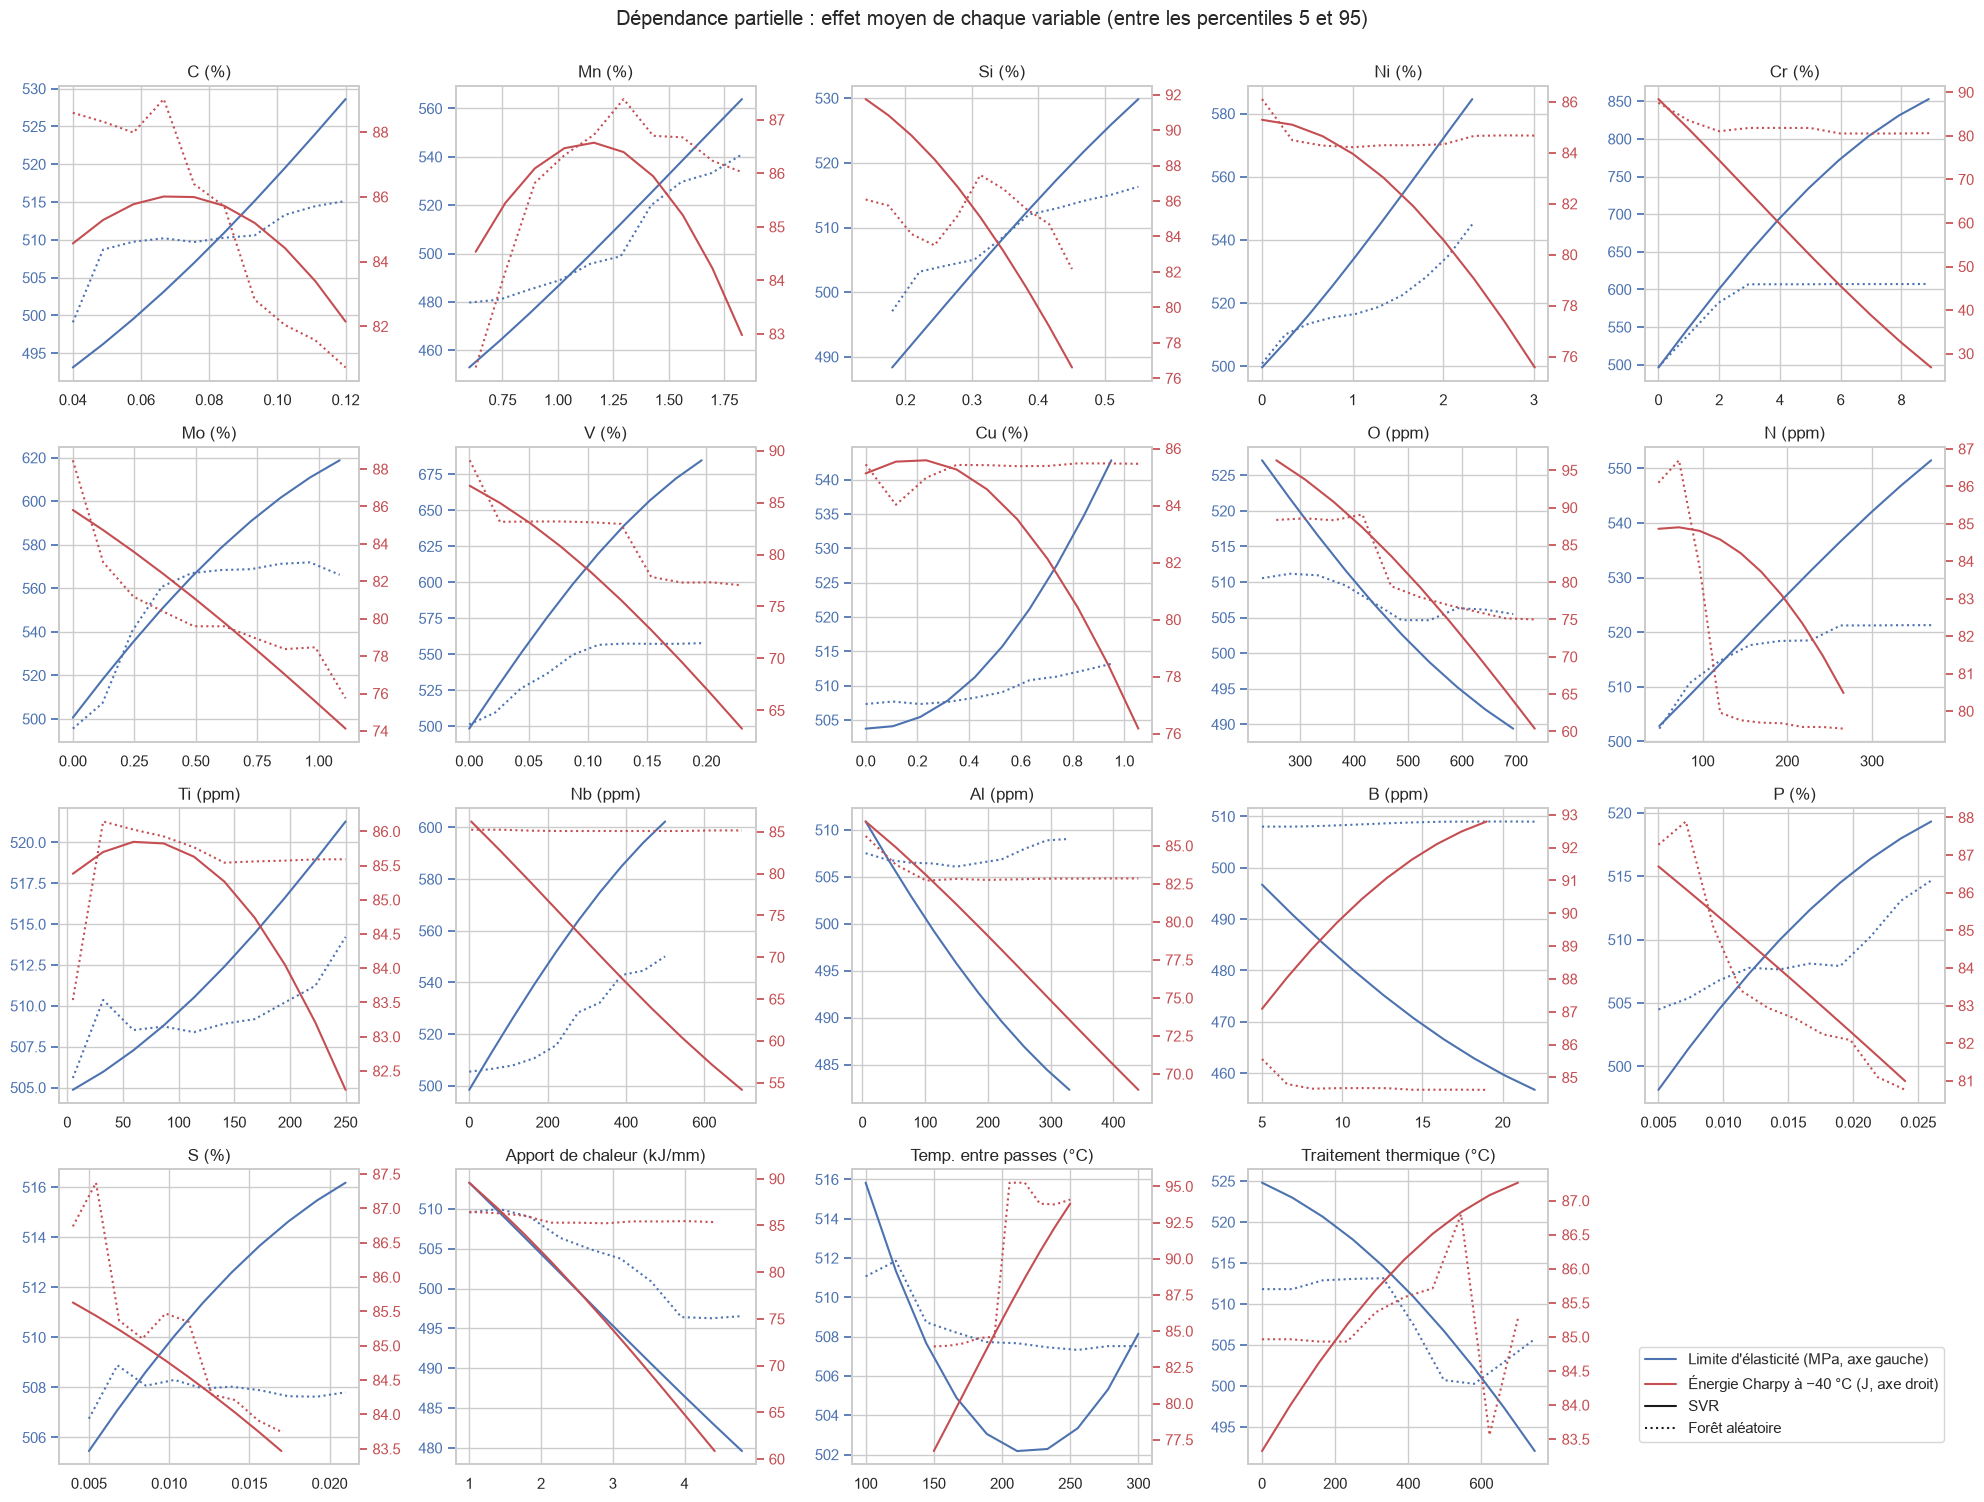

In [11]:
fig, axes = plt.subplots(len(FEATURES) // 5 + 1, 5, figsize=(20, 15))
for ax, feature in zip(axes.flat, FEATURES):
    ax2 = ax.twinx()
    for (target, axis, color) in [("Limite d'élasticité", ax, "C0"), ("Résilience Charpy", ax2, "C3")]:
        for model, ls in [("SVR", "-"), ("Forêt aléatoire", ":")]:
            c = curves.query("cible == @target and variable == @feature and modèle == @model")
            axis.plot(c["valeur"], c["prédiction"], ls, color=color)
    ax.set_title(FEATURES[feature]); ax.tick_params(axis="y", colors="C0"); ax2.tick_params(axis="y", colors="C3")
    ax2.grid(False)
for ax in axes.flat[len(FEATURES):]:
    ax.axis("off")
fig.legend(handles=[plt.Line2D([], [], color="C0", label="Limite d'élasticité (MPa, axe gauche)"),
                    plt.Line2D([], [], color="C3", label="Énergie Charpy à −40 °C (J, axe droit)"),
                    plt.Line2D([], [], color="k", ls="-", label="SVR"),
                    plt.Line2D([], [], color="k", ls=":", label="Forêt aléatoire")],
           loc="lower right", bbox_to_anchor=(0.98, 0.04), fontsize=11)
fig.suptitle("Dépendance partielle : effet moyen de chaque variable (entre les percentiles 5 et 95)", y=1.0)
plt.tight_layout();

Pour résumer, on mesure l'**effet** de chaque variable : la variation de la prédiction quand
on passe de sa valeur basse (percentile 5) à sa valeur haute (percentile 95). On note si les
deux modèles sont d'accord sur le sens de l'effet.

In [12]:
def effect(target, feature, model):
    c = curves.query("cible == @target and variable == @feature and modèle == @model")["prédiction"].to_numpy()
    return c[-1] - c[0]

rows = []
for feature, label in FEATURES.items():
    lo, hi = curves.query("variable == @feature and cible == \"Limite d'élasticité\"")["valeur"].agg(["min", "max"])
    row = {"variable": label, "plage (données Re)": f"{lo:.3g} → {hi:.3g}"}
    for target, short, tol in [("Limite d'élasticité", "Re (MPa)", 10), ("Résilience Charpy", "KV −40 °C (J)", 3)]:
        s, f = effect(target, feature, "SVR"), effect(target, feature, "Forêt aléatoire")
        row[f"effet SVR {short}"] = s
        row[f"effet forêt {short}"] = f
        if max(abs(s), abs(f)) < tol:
            agreement = "effet faible"
        elif min(abs(s), abs(f)) < tol:
            agreement = "un seul modèle"
        else:
            agreement = "oui" if np.sign(s) == np.sign(f) else "non"
        row[f"accord {short}"] = agreement
    rows.append(row)
effects = pd.DataFrame(rows).set_index("variable")
effects.round(0)

,plage (données Re),effet SVR Re (MPa),effet forêt Re (MPa),accord Re (MPa),effet SVR KV −40 °C (J),effet forêt KV −40 °C (J),accord KV −40 °C (J)
variable,,,,,,,
C (%),0.04 → 0.12,35.0,16.0,oui,-2.0,-8.0,un seul modèle
Mn (%),0.6 → 1.83,111.0,61.0,oui,-2.0,4.0,un seul modèle
Si (%),0.18 → 0.551,42.0,19.0,oui,-15.0,-4.0,oui
Ni (%),0 → 2.32,85.0,44.0,oui,-10.0,-1.0,un seul modèle
Cr (%),0 → 8.9,357.0,110.0,oui,-62.0,-7.0,oui
Mo (%),0 → 1.09,118.0,71.0,oui,-12.0,-13.0,oui
V (%),0 → 0.196,186.0,56.0,oui,-23.0,-12.0,oui
Cu (%),0 → 0.95,39.0,6.0,un seul modèle,-9.0,0.0,un seul modèle
O (ppm),230 → 695,-38.0,-5.0,un seul modèle,-36.0,-13.0,oui


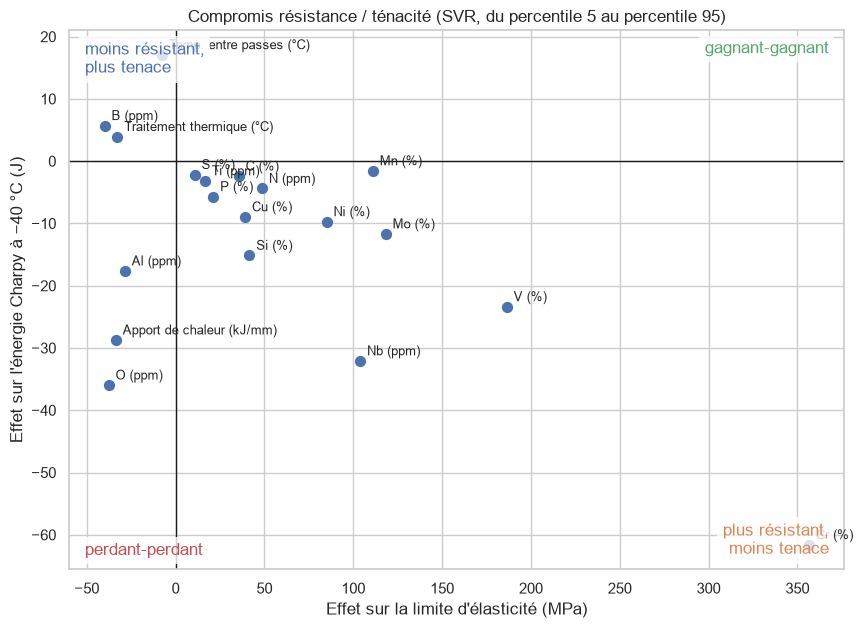

In [13]:
fig, ax = plt.subplots(figsize=(10, 7))
x = effects["effet SVR Re (MPa)"]; y = effects["effet SVR KV −40 °C (J)"]
ax.axhline(0, color="k", lw=1); ax.axvline(0, color="k", lw=1)
ax.scatter(x, y, s=50)
for label in effects.index:
    ax.annotate(label, (x[label], y[label]), textcoords="offset points", xytext=(5, 4), fontsize=9)
box = {"facecolor": "white", "alpha": 0.8, "edgecolor": "none"}
ax.set_xlabel("Effet sur la limite d'élasticité (MPa)")
ax.set_ylabel("Effet sur l'énergie Charpy à −40 °C (J)")
ax.set_title("Compromis résistance / ténacité (SVR, du percentile 5 au percentile 95)")
ax.text(0.98, 0.98, "gagnant-gagnant", transform=ax.transAxes, ha="right", va="top", color="C2", bbox=box)
ax.text(0.98, 0.02, "plus résistant,\nmoins tenace", transform=ax.transAxes, ha="right", va="bottom", color="C1", bbox=box)
ax.text(0.02, 0.02, "perdant-perdant", transform=ax.transAxes, ha="left", va="bottom", color="C3", bbox=box)
ax.text(0.02, 0.98, "moins résistant,\nplus tenace", transform=ax.transAxes, ha="left", va="top", color="C0", bbox=box);

## 7. Recommandations

### 7.1 Lecture des effets

Dans le tableau ci-dessus, « accord » indique si le SVR et la forêt aléatoire trouvent un
effet dans le même sens (« oui »), un effet net pour un seul des deux (« un seul modèle »),
des sens opposés (« non ») ou un effet négligeable pour les deux (« effet faible »). Les
effets de la forêt sont plus faibles, car elle ne prédit jamais au-delà des valeurs vues
(plateaux). Une recommandation est d'autant plus solide que les deux modèles s'accordent et
que l'effet est connu en métallurgie du soudage.

Ce que montrent les modèles :
- **Mn** augmente nettement la résistance (+60 à +110 MPa entre 0,6 et 1,8 %). La ténacité
  présente un **optimum vers 1,1–1,3 %** dans les deux modèles, puis diminue.
- **Cr, Mo, V, Nb** augmentent fortement la résistance mais **dégradent la ténacité** (Cr, Mo
  et V dans les deux modèles, Nb pour le SVR seulement). C'est le compromis résistance / ténacité classique.
- **L'oxygène** dégrade la ténacité dans les deux modèles (−13 à −36 J entre 230 et 700 ppm).
- **Un apport de chaleur élevé** réduit la résistance (deux modèles) et la ténacité (SVR).
- **Une température entre passes plus élevée** (de 150 à 250 °C) améliore la ténacité dans
  les deux modèles, avec un effet faible sur la résistance.
- **Les impuretés P, S, N** : petit gain de résistance, perte de ténacité.
- **Ni** : gain de résistance, mais **pas de gain de ténacité** visible dans ces données.
- **Le traitement thermique après soudage** baisse la résistance (SVR, environ −30 MPa) sans
  gain clair de ténacité.

### 7.2 Recommandations pratiques pour les soudeurs

Elles sont classées selon ce que le soudeur ou le responsable soudage contrôle réellement.

| Levier | Que faire concrètement | Ce que montrent les modèles | Confiance |
|---|---|---|---|
| **Choix du consommable : manganèse** | Choisir une électrode, un fil ou un couple fil/flux donnant **environ 1,0 à 1,4 % de Mn** dans le métal fondu (fiche technique du fabricant) | Résistance en hausse avec Mn ; ténacité maximale vers 1,1–1,3 % | **Forte** : deux modèles d'accord, cohérent avec les travaux d'Evans sur les soudures C-Mn [Evans & Bailey, 1997] |
| **Choix du consommable : carbone** | Préférer un métal fondu à **bas carbone (≤ 0,08 %)** | La résistance augmente avec C, la ténacité baisse au-delà de ~0,08 % | Moyenne |
| **Choix du consommable : éléments d'alliage** | N'utiliser des consommables alliés au **Cr, Mo, V, Nb** que si le cahier des charges l'exige (haute résistance, tenue à chaud). Dans ce cas, **prévoir des essais Charpy** | Forte hausse de résistance, perte de ténacité | **Forte** pour Cr, Mo et V ; moyenne pour Nb |
| **Limiter l'oxygène** | Préférer les **enrobages et flux basiques** aux rutiles ou acides, et un gaz de protection peu oxydant (moins de CO₂/O₂) ; garder une bonne protection gazeuse | L'oxygène est l'élément qui dégrade le plus la ténacité, après Cr | **Forte** : deux modèles d'accord ; les inclusions d'oxydes sont un facteur connu de fragilité [Grong, 1997] |
| **Apport de chaleur** | Le maintenir **modéré (vers 1 à 2 kJ/mm)**. Apport de chaleur = k × U × I / v (k : rendement du procédé, ex. 0,8 en MMA, 1,0 en arc submergé ; U tension ; I intensité ; v vitesse d'avance). Pour le réduire : avancer plus vite, baisser l'intensité ou la tension, faire **plus de passes plus fines** | Résistance (deux modèles) et ténacité (SVR) baissent quand l'apport de chaleur augmente | Moyenne à forte : effet connu (microstructure plus grossière) |
| **Température entre passes** | La **mesurer avant chaque passe** (thermomètre de contact, crayons thermosensibles) et la tenir dans une plage contrôlée ; dans les données, **200–250 °C** donne une meilleure ténacité que 150 °C | Ténacité en hausse de 150 à 250 °C (deux modèles), résistance peu affectée | Moyenne : peu de données hors 150–250 °C, ne pas extrapoler |
| **Impuretés (P, S, N)** | Utiliser des consommables à faibles P et S ; limiter l'azote par une bonne protection (**arc court**, débit de gaz adapté, pas de courants d'air) | Petite perte de ténacité quand P, S ou N augmentent | Moyenne |
| **Traitement thermique après soudage** | Le réaliser quand il est exigé (détensionnement), mais **ne pas compter sur lui pour améliorer la ténacité** et anticiper une baisse de résistance | Résistance en baisse (SVR, ~−30 MPa), pas de gain net de ténacité | Faible : effet dépendant de la composition |

**Pour la qualification des soudures** :
- le modèle de limite d'élasticité peut servir à **présélectionner** des combinaisons
  consommable / paramètres avant les essais, de préférence avec le gradient boosting et une
  marge de sécurité d'environ 50 MPa : on peut alors attendre environ 10 % de fausse
  acceptation et 30 % de faux rejets sur des recettes nouvelles (section 3) ;
- le modèle de ténacité n'est **pas assez fiable** pour se passer des essais Charpy : ils
  restent indispensables, en particulier pour les soudures alliées.

### 7.3 Limites

- **Corrélation n'est pas causalité** : les effets sont ceux appris sur des données
  publiées. Certains éléments varient ensemble (Cr et Mo) et une partie de l'effet peut venir
  des différences entre publications.
- **Domaine de validité** : les recommandations ne valent qu'à l'intérieur des plages
  étudiées (percentiles 5–95), et surtout pour les soudures C-Mn faiblement alliées, qui
  forment l'essentiel de la base.
- **La ténacité est mal prédite** (R² ≈ 0,28) : les recommandations sur la ténacité sont
  des tendances à confirmer.
- **Hydrogène, préparation des bords, position de soudage, épaisseur** ne sont pas dans la
  base : les bonnes pratiques habituelles sur ces points (étuvage des électrodes basiques,
  nettoyage, préchauffage) restent nécessaires.
- Pour aller plus loin, il faudrait des **plans d'expériences** ciblés (faire varier un
  paramètre à la fois) pour confirmer les effets les plus importants : Mn, O, apport de
  chaleur, température entre passes.

## 8. Conclusion générale

- **Approche retenue** : un SVR par propriété (limite d'élasticité, résilience Charpy à
  température donnée), avec le pré-traitement du notebook 03 et une validation croisée
  groupée par publication.
- **Performances sur des publications jamais vues** : environ 67 MPa d'erreur (R² ≈ 0,45,
  intervalle de confiance à 95 % d'environ 57 à 78 MPa) pour la limite d'élasticité ;
  environ 40 J (R² ≈ 0,28, intervalle d'environ 32 à 49 J) pour le Charpy. Le SVR est au moins
  aussi bon que la forêt aléatoire, mais l'écart n'est pas significatif.
- **Gradient boosting** : meilleur modèle pour la limite d'élasticité (≈ 63 MPa, R² ≈ 0,50)
  et meilleur compromis pour la présélection, sans écart significatif avec le SVR ; pas
  meilleur que la température seule pour le Charpy.
- **Semi-supervisé** : pas de gain, ni avec le self-training ni avec la régularisation de
  variété. Les données non étiquetées apportent peu d'information nouvelle, et la limite
  vient du manque de publications variées, pas du manque d'étiquettes.
- **Bonne soudure** : un consommable bas carbone, autour de 1,0–1,4 % de Mn, peu d'oxygène et
  d'impuretés, un apport de chaleur modéré et une température entre passes contrôlée. Les
  éléments d'alliage durcissants ne sont à utiliser que si la résistance l'exige, en
  vérifiant la ténacité.

### Références

- Evans, G. M., & Bailey, N. (1997). *Metallurgy of Basic Weld Metal*. Abington Publishing.
- Grong, Ø. (1997). *Metallurgical Modelling of Welding* (2ᵉ éd.). The Institute of Materials.
- Cool, T., Bhadeshia, H. K. D. H., & MacKay, D. J. C. (1997). The yield and ultimate tensile strength of steel welds. *Materials Science and Engineering A*, 223.
- NF EN ISO 2560 : Produits consommables pour le soudage — Électrodes enrobées pour le soudage manuel à l'arc des aciers non alliés et à grains fins — Classification.
- NF EN 1011-1 : Soudage — Recommandations pour le soudage des matériaux métalliques — Partie 1 : lignes directrices générales pour le soudage à l'arc (rendement thermique des procédés).